# Medical Diagnosis Expert System
Comparison of Rule-Based Expert System, Forward Chaining, Backward Chaining, and Fuzzy Logic for Clinical Decision Support.

This project implements and evaluates four knowledge-based artificial intelligence methods for clinical diagnosis using the 27 formal rules defined in `rules.txt`. The system evaluates the 200 patient records from `medical_diagnosis_200.csv`, benchmarks computational and diagnostic performance, and provides a unified interactive Gradio interface with dynamic method selection.


In [1]:
import sys
import os
import subprocess

# install dependencies if running in colab
for pkg in ["gradio", "pandas", "numpy", "matplotlib"]:
    try:
        __import__(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", pkg, "-q"])

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import json

# candidate paths for dataset
csv_candidates = [
    "medical_diagnosis_200_enriched.csv",
    "medical_diagnosis_200.csv",
    "medical_diagnosis_200 (1).csv",
    os.path.expanduser("~/Downloads/medical_diagnosis_200_enriched.csv"),
    os.path.expanduser("~/Downloads/medical_diagnosis_200.csv"),
    os.path.expanduser("~/Downloads/medical_diagnosis_200 (1).csv"),
    "/content/medical_diagnosis_200_enriched.csv",
    "/content/medical_diagnosis_200.csv"
]

dataset_path = None
for p in csv_candidates:
    if os.path.exists(p):
        dataset_path = p
        break

if dataset_path is not None:
    df = pd.read_csv(dataset_path)
    print(f"Loaded local dataset from: {dataset_path}")
else:
    # load remote raw repository copy
    remote_url = "https://raw.githubusercontent.com/royaldinan/medical-diagnosis-expert-system/main/medical_diagnosis_200_enriched.csv"
    try:
        df = pd.read_csv(remote_url)
        print("Loaded dataset from GitHub repository.")
    except Exception as e:
        print(f"Remote fetch failed: {e}. Generating local fallback dataset.")
        df = pd.DataFrame()

# verify and normalize required clinical columns
required_defaults = {
    "fever_C": 37.0, "cough": 0, "fatigue": 0, "headache": 0, "nausea": 0,
    "oxygen_spo2": 98, "heart_rate": 75, "rash": "no", "bleeding": "no",
    "diarrhea": "no", "vomiting": "no", "sore_throat": "no", "body_pain": "no",
    "stomach_pain": 0, "appetite_loss": "no", "wheezing": "no", "chest_pain": "no",
    "shortness_of_breath": "no", "platelet": 250000, "joint_pain": 0,
    "night_sweats": "no", "stiff_neck": "no", "dizziness": "no", "confusion": "no",
    "sweating": "no", "blood_pressure": 120, "thirst": 0, "urination": "normal",
    "weight_loss": "no", "skin_rash": "no", "itching": "no", "eye_redness": "no",
    "watery_eyes": "no", "back_pain": 0, "stiffness": "no"
}

for col, val in required_defaults.items():
    if col not in df.columns:
        df[col] = val

if "patient_id" not in df.columns:
    df["patient_id"] = list(range(1, len(df) + 1))
if "diagnosis" not in df.columns:
    df["diagnosis"] = "Undetermined"

print(f"Dataset ready: {df.shape[0]} patients, {df.shape[1]} columns.")
df[["patient_id", "diagnosis", "fever_C", "cough", "oxygen_spo2", "heart_rate"]].head(5)


Loaded dataset from GitHub repository.
Dataset ready: 200 patients, 41 columns.


,patient_id,diagnosis,fever_C,cough,oxygen_spo2,heart_rate
0,96,Common Cold,37.6,6,100,74
1,16,Bronchitis,37.6,9,97,94
2,31,Common Cold,37.7,8,100,64
3,159,COVID-19,38.7,10,89,66
4,129,Gastroenteritis,38.5,3,92,73


In [2]:
# clinical rule base representing rules.txt
CLINICAL_RULES = [
    # 1. common infections
    {"id": "R01", "disease": "Flu", "cat": "Common infections",
     "conditions": lambda p: p["fever"] > 38.0 and p["cough"] > 6,
     "desc": "fever > 38 AND cough > 6"},
    {"id": "R02", "disease": "Measles", "cat": "Common infections",
     "conditions": lambda p: p["fever"] > 39.0 and p["rash"] == "yes",
     "desc": "fever > 39 AND rash == 'yes'"},
    {"id": "R03", "disease": "Common Cold", "cat": "Common infections",
     "conditions": lambda p: p["fever"] > 37.0 and p["sore_throat"] == "yes" and p["cough"] > 4,
     "desc": "fever > 37 AND sore_throat == 'yes' AND cough > 4"},
    {"id": "R04", "disease": "Viral Fever", "cat": "Common infections",
     "conditions": lambda p: p["fever"] > 38.0 and p["fatigue"] > 6 and p["body_pain"] == "yes",
     "desc": "fever > 38 AND fatigue > 6 AND body_pain == 'yes'"},

    # 2. gastrointestinal
    {"id": "R05", "disease": "Food Poisoning", "cat": "Gastrointestinal",
     "conditions": lambda p: p["nausea"] > 6 and p["vomiting"] == "yes" and p["diarrhea"] == "yes",
     "desc": "nausea > 6 AND vomiting == 'yes' AND diarrhea == 'yes'"},
    {"id": "R06", "disease": "Gastroenteritis", "cat": "Gastrointestinal",
     "conditions": lambda p: p["stomach_pain"] > 7 and p["vomiting"] == "yes" and p["fever"] > 37.5,
     "desc": "stomach_pain > 7 AND vomiting == 'yes' AND fever > 37.5"},
    {"id": "R07", "disease": "Indigestion", "cat": "Gastrointestinal",
     "conditions": lambda p: p["nausea"] > 5 and p["appetite_loss"] == "yes",
     "desc": "nausea > 5 AND appetite_loss == 'yes'"},

    # 3. respiratory
    {"id": "R08", "disease": "Pneumonia", "cat": "Respiratory",
     "conditions": lambda p: p["oxygen_spo2"] < 92 and p["cough"] > 7 and p["fever"] > 38.0,
     "desc": "oxygen_spo2 < 92 AND cough > 7 AND fever > 38"},
    {"id": "R09", "disease": "Bronchitis", "cat": "Respiratory",
     "conditions": lambda p: p["cough"] > 8 and p["wheezing"] == "yes" and p["chest_pain"] == "yes",
     "desc": "cough > 8 AND wheezing == 'yes' AND chest_pain == 'yes'"},
    {"id": "R10", "disease": "Asthma", "cat": "Respiratory",
     "conditions": lambda p: p["cough"] > 6 and p["shortness_of_breath"] == "yes" and p["fatigue"] > 6,
     "desc": "cough > 6 AND shortness_of_breath == 'yes' AND fatigue > 6"},

    # 4. vector-borne
    {"id": "R11", "disease": "Dengue", "cat": "Vector-borne",
     "conditions": lambda p: p["fever"] > 38.0 and p["headache"] > 6 and p["rash"] == "yes",
     "desc": "fever > 38 AND headache > 6 AND rash == 'yes'"},
    {"id": "R12", "disease": "Dengue Hemorrhagic Fever", "cat": "Vector-borne",
     "conditions": lambda p: p["fever"] > 39.0 and p["bleeding"] == "yes" and p["platelet"] < 100000,
     "desc": "fever > 39 AND bleeding == 'yes' AND platelet < 100000"},
    {"id": "R13", "disease": "Chikungunya", "cat": "Vector-borne",
     "conditions": lambda p: p["fever"] > 37.5 and p["joint_pain"] > 7,
     "desc": "fever > 37.5 AND joint_pain > 7"},
    {"id": "R14", "disease": "Tuberculosis", "cat": "Vector-borne",
     "conditions": lambda p: p["fever"] > 38.0 and p["night_sweats"] == "yes" and p["cough"] > 5,
     "desc": "fever > 38 AND night_sweats == 'yes' AND cough > 5"},

    # 5. neurological
    {"id": "R15", "disease": "Meningitis", "cat": "Neurological",
     "conditions": lambda p: p["headache"] > 8 and p["fever"] > 38.0 and p["stiff_neck"] == "yes",
     "desc": "headache > 8 AND fever > 38 AND stiff_neck == 'yes'"},
    {"id": "R16", "disease": "Migraine", "cat": "Neurological",
     "conditions": lambda p: p["headache"] > 7 and p["dizziness"] == "yes" and p["fatigue"] > 6,
     "desc": "headache > 7 AND dizziness == 'yes' AND fatigue > 6"},
    {"id": "R17", "disease": "Chronic Fatigue Syndrome", "cat": "Neurological",
     "conditions": lambda p: p["fatigue"] > 8 and p["confusion"] == "yes",
     "desc": "fatigue > 8 AND confusion == 'yes'"},

    # 6. cardiovascular
    {"id": "R18", "disease": "Cardiac Stress", "cat": "Cardiovascular",
     "conditions": lambda p: p["heart_rate"] > 120 and p["fatigue"] > 8,
     "desc": "heart_rate > 120 AND fatigue > 8"},
    {"id": "R19", "disease": "Heart Attack", "cat": "Cardiovascular",
     "conditions": lambda p: p["chest_pain"] == "yes" and p["shortness_of_breath"] == "yes" and p["sweating"] == "yes",
     "desc": "chest_pain == 'yes' AND shortness_of_breath == 'yes' AND sweating == 'yes'"},
    {"id": "R20", "disease": "Hypertension", "cat": "Cardiovascular",
     "conditions": lambda p: p["blood_pressure"] > 140 and p["headache"] > 6,
     "desc": "blood_pressure > 140 AND headache > 6"},

    # 7. metabolic
    {"id": "R21", "disease": "Diabetes", "cat": "Metabolic",
     "conditions": lambda p: p["thirst"] > 7 and p["urination"] == "frequent" and p["fatigue"] > 5,
     "desc": "thirst > 7 AND urination == 'frequent' AND fatigue > 5"},
    {"id": "R22", "disease": "Thyroid Disorder", "cat": "Metabolic",
     "conditions": lambda p: p["weight_loss"] == "yes" and p["appetite_loss"] == "yes" and p["fatigue"] > 7,
     "desc": "weight_loss == 'yes' AND appetite_loss == 'yes' AND fatigue > 7"},

    # 8. others
    {"id": "R23", "disease": "Allergic Reaction", "cat": "Others",
     "conditions": lambda p: (p["skin_rash"] == "yes" or p["rash"] == "yes") and p["itching"] == "yes",
     "desc": "skin_rash == 'yes' AND itching == 'yes'"},
    {"id": "R24", "disease": "Conjunctivitis", "cat": "Others",
     "conditions": lambda p: p["eye_redness"] == "yes" and p["watery_eyes"] == "yes",
     "desc": "eye_redness == 'yes' AND watery_eyes == 'yes'"},
    {"id": "R25", "disease": "Muscle Strain", "cat": "Others",
     "conditions": lambda p: p["back_pain"] > 7 and p["fatigue"] > 6,
     "desc": "back_pain > 7 AND fatigue > 6"},
    {"id": "R26", "disease": "Arthritis", "cat": "Others",
     "conditions": lambda p: p["joint_pain"] > 6 and p["stiffness"] == "yes",
     "desc": "joint_pain > 6 AND stiffness == 'yes'"},
    {"id": "R27", "disease": "Healthy", "cat": "Others",
     "conditions": lambda p: p["fever"] < 37.5 and max(p.get("cough",0), p.get("fatigue",0), p.get("headache",0), p.get("nausea",0), p.get("stomach_pain",0), p.get("joint_pain",0), p.get("back_pain",0)) <= 2 and p.get("rash","no")=="no" and p.get("vomiting","no")=="no" and p.get("diarrhea","no")=="no" and p.get("chest_pain","no")=="no",
     "desc": "fever < 37.5 AND all symptoms == 'low'"}
]

def normalize_patient(raw):
    # parse patient attributes into standard format
    p = {}
    p["fever"] = float(raw.get("fever_C", raw.get("fever", 37.0)))
    p["cough"] = int(float(raw.get("cough", 0)))
    p["fatigue"] = int(float(raw.get("fatigue", 0)))
    p["headache"] = int(float(raw.get("headache", 0)))
    p["nausea"] = int(float(raw.get("nausea", 0)))
    p["oxygen_spo2"] = int(float(raw.get("oxygen_spo2", 98)))
    p["heart_rate"] = int(float(raw.get("heart_rate", 75)))
    p["stomach_pain"] = int(float(raw.get("stomach_pain", 0)))
    p["platelet"] = int(float(raw.get("platelet", 250000)))
    p["joint_pain"] = int(float(raw.get("joint_pain", 0)))
    p["back_pain"] = int(float(raw.get("back_pain", 0)))
    p["thirst"] = int(float(raw.get("thirst", 0)))
    p["blood_pressure"] = int(float(raw.get("blood_pressure", 120)))

    str_keys = ["rash", "bleeding", "diarrhea", "vomiting", "sore_throat", "body_pain",
                "appetite_loss", "wheezing", "chest_pain", "shortness_of_breath",
                "night_sweats", "stiff_neck", "dizziness", "confusion", "sweating",
                "urination", "weight_loss", "skin_rash", "itching", "eye_redness",
                "watery_eyes", "stiffness"]
    for k in str_keys:
        v = str(raw.get(k, "no")).strip().lower()
        p[k] = v if v else "no"
    if p["rash"] == "yes" and p["skin_rash"] == "no":
        p["skin_rash"] = "yes"
    return p


In [3]:
# method 1: rule-based expert system
class RuleBasedExpertSystem:
    def __init__(self, rules):
        self.rules = rules

    def diagnose(self, raw_patient):
        p = normalize_patient(raw_patient)
        fired = []

        # evaluate rule preconditions
        for r in self.rules:
            try:
                if r["conditions"](p):
                    fired.append(r)
            except Exception:
                pass

        if not fired:
            return {
                "method": "Rule-Based Expert System",
                "diagnosis": "Undetermined / Inconclusive",
                "confidence": 0.0,
                "primary_rule": None,
                "fired_rules": [],
                "reasoning": "No clinical production rule fired for the observed symptom profile."
            }

        # resolve conflicts via precondition specificity
        def condition_count(rule):
            return len(rule["desc"].split(" AND "))

        fired.sort(key=condition_count, reverse=True)
        winner = fired[0]

        return {
            "method": "Rule-Based Expert System",
            "diagnosis": winner["disease"],
            "confidence": 1.0 if len(fired) == 1 else 0.88,
            "primary_rule": winner["id"],
            "fired_rules": [f"{r['id']}: {r['disease']} ({r['desc']})" for r in fired],
            "reasoning": f"Matched Rule {winner['id']} ({winner['desc']}) with specificity rank {condition_count(winner)}."
        }

rbs_engine = RuleBasedExpertSystem(CLINICAL_RULES)


In [4]:
# method 2: forward chaining inference engine
class ForwardChainingEngine:
    def __init__(self, rules):
        self.rules = rules

    def infer(self, raw_patient):
        p = normalize_patient(raw_patient)
        wm = dict(p)
        trace = []
        cycle = 1

        # cycle 1: abstract raw vitals into clinical states
        abstractions = [
            ("hyperthermia", lambda m: m["fever"] > 38.0, "fever > 38.0"),
            ("mild_pyrexia", lambda m: 37.0 < m["fever"] <= 38.0, "37.0 < fever <= 38.0"),
            ("high_grade_fever", lambda m: m["fever"] > 39.0, "fever > 39.0"),
            ("severe_cough", lambda m: m["cough"] > 6, "cough > 6"),
            ("moderate_cough", lambda m: 4 < m["cough"] <= 6, "4 < cough <= 6"),
            ("hypoxemia", lambda m: m["oxygen_spo2"] < 92, "oxygen_spo2 < 92"),
            ("severe_fatigue", lambda m: m["fatigue"] > 6, "fatigue > 6"),
            ("critical_fatigue", lambda m: m["fatigue"] > 8, "fatigue > 8"),
            ("severe_headache", lambda m: m["headache"] > 6, "headache > 6"),
            ("critical_headache", lambda m: m["headache"] > 8, "headache > 8"),
            ("severe_nausea", lambda m: m["nausea"] > 6, "nausea > 6"),
            ("severe_abdominal_pain", lambda m: m["stomach_pain"] > 7, "stomach_pain > 7"),
            ("severe_arthralgia", lambda m: m["joint_pain"] > 7, "joint_pain > 7"),
            ("tachycardia", lambda m: m["heart_rate"] > 120, "heart_rate > 120"),
            ("hypertensive_bp", lambda m: m["blood_pressure"] > 140, "blood_pressure > 140"),
            ("thrombocytopenia", lambda m: m["platelet"] < 100000, "platelet < 100000"),
            ("polydipsia", lambda m: m["thirst"] > 7, "thirst > 7"),
            ("severe_lumbar_pain", lambda m: m["back_pain"] > 7, "back_pain > 7"),
        ]

        asserted_c1 = []
        for fact_name, fn, cond_text in abstractions:
            if fn(wm) and fact_name not in wm:
                wm[fact_name] = True
                asserted_c1.append(f"{fact_name} [{cond_text}]")

        if asserted_c1:
            trace.append(f"Cycle {cycle} (Clinical Abstraction): Derived {', '.join(asserted_c1)}")
            cycle += 1

        # cycle 2: deduce intermediate clinical syndromes
        syndromes = [
            ("acute_respiratory_syndrome", lambda m: m.get("hyperthermia") and m.get("severe_cough"), "hyperthermia AND severe_cough"),
            ("gastroenteritis_syndrome", lambda m: m.get("severe_abdominal_pain") and m.get("vomiting") == "yes" and m["fever"] > 37.5, "severe_abdominal_pain AND vomiting AND fever > 37.5"),
            ("food_poisoning_syndrome", lambda m: m.get("severe_nausea") and m.get("vomiting") == "yes" and m.get("diarrhea") == "yes", "severe_nausea AND vomiting AND diarrhea"),
            ("lower_respiratory_distress", lambda m: m.get("hypoxemia") and m.get("severe_cough") and m.get("hyperthermia"), "hypoxemia AND severe_cough AND hyperthermia"),
            ("meningeal_syndrome", lambda m: m.get("critical_headache") and m.get("hyperthermia") and m.get("stiff_neck") == "yes", "critical_headache AND hyperthermia AND stiff_neck"),
            ("bronchial_syndrome", lambda m: m["cough"] > 8 and m["wheezing"] == "yes" and m["chest_pain"] == "yes", "cough > 8 AND wheezing AND chest_pain"),
            ("dengue_syndrome", lambda m: m.get("hyperthermia") and m.get("severe_headache") and m["rash"] == "yes", "hyperthermia AND severe_headache AND rash"),
        ]

        asserted_c2 = []
        for syn_name, fn, cond_text in syndromes:
            if fn(wm) and syn_name not in wm:
                wm[syn_name] = True
                asserted_c2.append(f"{syn_name} [{cond_text}]")

        if asserted_c2:
            trace.append(f"Cycle {cycle} (Syndrome Deduction): Derived {', '.join(asserted_c2)}")
            cycle += 1

        # cycle 3: match terminal disease classification
        candidates = []
        for r in self.rules:
            try:
                if r["conditions"](p):
                    candidates.append(r)
            except Exception:
                pass

        if not candidates:
            trace.append(f"Cycle {cycle} (Terminal Goal): Working memory saturated without terminal diagnosis.")
            return {
                "method": "Forward Chaining",
                "diagnosis": "Undetermined / Inconclusive",
                "confidence": 0.0,
                "cycles": cycle,
                "trace": trace,
                "reasoning": "Inference completed without matching terminal disease production rules."
            }

        def condition_count(rule):
            return len(rule["desc"].split(" AND "))

        candidates.sort(key=condition_count, reverse=True)
        winner = candidates[0]
        trace.append(f"Cycle {cycle} (Terminal Goal): Fired {winner['id']} -> Confirmed {winner['disease']}.")

        return {
            "method": "Forward Chaining",
            "diagnosis": winner["disease"],
            "confidence": 0.95,
            "cycles": cycle,
            "primary_rule": winner["id"],
            "trace": trace,
            "reasoning": f"Forward inference confirmed {winner['disease']} through {cycle} deduction cycles."
        }

fc_engine = ForwardChainingEngine(CLINICAL_RULES)


In [5]:
# method 3: backward chaining inference engine
class BackwardChainingEngine:
    def __init__(self, rules):
        self.rules = rules

    def evaluate_hypothesis(self, disease, raw_patient):
        p = normalize_patient(raw_patient)
        matched_rules = [r for r in self.rules if r["disease"].lower() == disease.lower()]
        if not matched_rules:
            return {
                "goal": disease,
                "proven": False,
                "trace": [f"No rule exists in knowledge base concluding '{disease}'."],
                "missing_conditions": []
            }

        rule = matched_rules[0]
        subgoals = []
        missing = []
        parts = rule["desc"].split(" AND ")
        all_satisfied = True

        # recursive sub-goal verification
        for part in parts:
            part = part.strip()
            passed = False
            curr = None

            if ">" in part:
                var, val = part.split(">")
                var, val = var.strip(), float(val.strip())
                curr = p.get(var, 0)
                passed = curr > val
                subgoals.append(f"Verify sub-goal [{var} > {val}]: Observed {curr} -> {'PASSED' if passed else 'FAILED'}")
            elif "<" in part:
                var, val = part.split("<")
                var, val = var.strip(), float(val.strip())
                curr = p.get(var, 0)
                passed = curr < val
                subgoals.append(f"Verify sub-goal [{var} < {val}]: Observed {curr} -> {'PASSED' if passed else 'FAILED'}")
            elif "==" in part:
                var, val = part.split("==")
                var, val = var.strip(), val.strip().replace("'", "").replace('"', "")
                curr = p.get(var, "no")
                passed = str(curr).lower() == str(val).lower()
                subgoals.append(f"Verify sub-goal [{var} == '{val}']: Observed '{curr}' -> {'PASSED' if passed else 'FAILED'}")
            elif "all symptoms == 'low'" in part:
                passed = rule["conditions"](p)
                subgoals.append(f"Verify sub-goal [all symptoms are low]: -> {'PASSED' if passed else 'FAILED'}")

            if not passed:
                all_satisfied = False
                missing.append(part)

        return {
            "goal": rule["disease"],
            "proven": all_satisfied,
            "rule_id": rule["id"],
            "trace": subgoals,
            "missing_conditions": missing
        }

    def infer(self, raw_patient, target_hypothesis=None):
        if target_hypothesis and target_hypothesis != "Auto (Evaluate All Candidates)":
            eval_res = self.evaluate_hypothesis(target_hypothesis, raw_patient)
            return {
                "method": "Backward Chaining",
                "diagnosis": eval_res["goal"] if eval_res["proven"] else "Undetermined / Inconclusive",
                "goal_tested": eval_res["goal"],
                "proven": eval_res["proven"],
                "confidence": 0.95 if eval_res["proven"] else 0.0,
                "trace": eval_res["trace"],
                "missing": eval_res["missing_conditions"],
                "reasoning": f"Hypothesis '{target_hypothesis}' was {'PROVEN' if eval_res['proven'] else 'REFUTED'}."
            }

        # auto-evaluate prioritized candidates
        evaluations = []
        proven_disease = None
        best_eval = None

        for r in self.rules:
            res = self.evaluate_hypothesis(r["disease"], raw_patient)
            evaluations.append(res)
            if res["proven"] and not proven_disease:
                proven_disease = res["goal"]
                best_eval = res

        if proven_disease:
            return {
                "method": "Backward Chaining",
                "diagnosis": proven_disease,
                "goal_tested": proven_disease,
                "proven": True,
                "confidence": 0.95,
                "trace": best_eval["trace"],
                "missing": [],
                "reasoning": f"Goal hypothesis '{proven_disease}' confirmed by complete sub-goal satisfaction."
            }
        else:
            evaluations.sort(key=lambda x: len(x["missing_conditions"]))
            closest = evaluations[0]
            return {
                "method": "Backward Chaining",
                "diagnosis": "Undetermined / Inconclusive",
                "goal_tested": closest["goal"],
                "proven": False,
                "confidence": 0.0,
                "trace": closest["trace"],
                "missing": closest["missing_conditions"],
                "reasoning": f"Closest candidate '{closest['goal']}' refuted due to {len(closest['missing_conditions'])} unsatisfied conditions."
            }

bc_engine = BackwardChainingEngine(CLINICAL_RULES)


In [6]:
# method 4: fuzzy logic mamdani inference engine
class FuzzyLogicEngine:
    def __init__(self, rules):
        self.rules = rules

    def _trap(self, x, a, b, c, d):
        if x <= a or x >= d:
            return 0.0
        if b <= x <= c:
            return 1.0
        if a < x < b:
            return (x - a) / (b - a) if b > a else 1.0
        return (d - x) / (d - c) if d > c else 1.0

    def _tri(self, x, a, b, c):
        if x <= a or x >= c:
            return 0.0
        if x == b:
            return 1.0
        if a < x < b:
            return (x - a) / (b - a) if b > a else 1.0
        return (c - x) / (c - b) if c > b else 1.0

    def infer(self, raw_patient):
        p = normalize_patient(raw_patient)

        # fuzzification of continuous vitals
        fever = p["fever"]
        cough = p["cough"]
        fatigue = p["fatigue"]
        headache = p["headache"]
        nausea = p["nausea"]
        spo2 = p["oxygen_spo2"]
        hr = p["heart_rate"]
        bp = p["blood_pressure"]
        thirst = p["thirst"]
        joint = p["joint_pain"]
        back = p["back_pain"]
        stomach = p["stomach_pain"]
        platelet = p["platelet"]

        mf = {
            "fever_normal": self._trap(fever, 34.0, 35.0, 37.0, 37.4),
            "fever_mild": self._tri(fever, 37.0, 37.6, 38.3),
            "fever_high": self._trap(fever, 37.8, 38.4, 42.0, 43.0),
            "fever_extreme": self._trap(fever, 38.8, 39.3, 42.0, 43.0),

            "cough_mild": self._trap(cough, 0, 0, 2, 4),
            "cough_mod": self._tri(cough, 3, 5, 7),
            "cough_severe": self._trap(cough, 6, 7.5, 10, 10),

            "spo2_hypoxic": self._trap(spo2, 60, 60, 89, 92),
            "spo2_borderline": self._tri(spo2, 90, 93, 96),
            "spo2_normal": self._trap(spo2, 94, 97, 100, 100),

            "fatigue_high": self._trap(fatigue, 5, 7, 10, 10),
            "headache_high": self._trap(headache, 5, 7, 10, 10),
            "headache_severe": self._trap(headache, 7, 8.5, 10, 10),
            "nausea_high": self._trap(nausea, 5, 6.5, 10, 10),
            "hr_tachycardia": self._trap(hr, 105, 120, 200, 200),
            "bp_hypertension": self._trap(bp, 130, 142, 220, 220),
            "platelet_low": self._trap(platelet, 0, 0, 85000, 100000),
            "thirst_high": self._trap(thirst, 5, 7.5, 10, 10),
            "joint_high": self._trap(joint, 5, 7.5, 10, 10),
            "back_high": self._trap(back, 5, 7.5, 10, 10),
            "stomach_high": self._trap(stomach, 5, 7.5, 10, 10),
        }

        # evaluate fuzzy production rules using t-norm min conjunction
        scores = {}
        scores["Flu"] = min(mf["fever_high"], mf["cough_severe"])
        scores["Measles"] = min(mf["fever_extreme"], 1.0 if p["rash"] == "yes" else 0.0)

        cold_fever = max(mf["fever_mild"], mf["fever_high"])
        cold_cough = max(mf["cough_mod"], mf["cough_severe"])
        cold_throat = 1.0 if p["sore_throat"] == "yes" else 0.0
        scores["Common Cold"] = min(cold_fever, cold_throat, cold_cough)

        scores["Viral Fever"] = min(mf["fever_high"], mf["fatigue_high"], 1.0 if p["body_pain"] == "yes" else 0.0)
        scores["Food Poisoning"] = min(mf["nausea_high"], 1.0 if p["vomiting"] == "yes" else 0.0, 1.0 if p["diarrhea"] == "yes" else 0.0)
        scores["Gastroenteritis"] = min(mf["stomach_high"], 1.0 if p["vomiting"] == "yes" else 0.0, max(mf["fever_mild"], mf["fever_high"]))
        scores["Indigestion"] = min(mf["nausea_high"], 1.0 if p["appetite_loss"] == "yes" else 0.0)

        scores["Pneumonia"] = min(mf["spo2_hypoxic"], mf["cough_severe"], mf["fever_high"])
        scores["Bronchitis"] = min(mf["cough_severe"], 1.0 if p["wheezing"] == "yes" else 0.0, 1.0 if p["chest_pain"] == "yes" else 0.0)
        scores["Asthma"] = min(mf["cough_severe"], 1.0 if p["shortness_of_breath"] == "yes" else 0.0, mf["fatigue_high"])

        scores["Dengue"] = min(mf["fever_high"], mf["headache_high"], 1.0 if p["rash"] == "yes" else 0.0)
        scores["Dengue Hemorrhagic Fever"] = min(mf["fever_extreme"], 1.0 if p["bleeding"] == "yes" else 0.0, mf["platelet_low"])
        scores["Chikungunya"] = min(max(mf["fever_mild"], mf["fever_high"]), mf["joint_high"])
        scores["Tuberculosis"] = min(mf["fever_high"], 1.0 if p["night_sweats"] == "yes" else 0.0, max(mf["cough_mod"], mf["cough_severe"]))

        scores["Meningitis"] = min(mf["headache_severe"], mf["fever_high"], 1.0 if p["stiff_neck"] == "yes" else 0.0)
        scores["Migraine"] = min(mf["headache_high"], 1.0 if p["dizziness"] == "yes" else 0.0, mf["fatigue_high"])
        scores["Chronic Fatigue Syndrome"] = min(mf["fatigue_high"], 1.0 if p["confusion"] == "yes" else 0.0)

        scores["Cardiac Stress"] = min(mf["hr_tachycardia"], mf["fatigue_high"])
        scores["Heart Attack"] = min(1.0 if p["chest_pain"] == "yes" else 0.0, 1.0 if p["shortness_of_breath"] == "yes" else 0.0, 1.0 if p["sweating"] == "yes" else 0.0)
        scores["Hypertension"] = min(mf["bp_hypertension"], mf["headache_high"])

        scores["Diabetes"] = min(mf["thirst_high"], 1.0 if p["urination"] == "frequent" else 0.0, mf["fatigue_high"])
        scores["Thyroid Disorder"] = min(1.0 if p["weight_loss"] == "yes" else 0.0, 1.0 if p["appetite_loss"] == "yes" else 0.0, mf["fatigue_high"])

        scores["Allergic Reaction"] = min(1.0 if (p["skin_rash"] == "yes" or p["rash"] == "yes") else 0.0, 1.0 if p["itching"] == "yes" else 0.0)
        scores["Conjunctivitis"] = min(1.0 if p["eye_redness"] == "yes" else 0.0, 1.0 if p["watery_eyes"] == "yes" else 0.0)
        scores["Muscle Strain"] = min(mf["back_high"], mf["fatigue_high"])
        scores["Arthritis"] = min(mf["joint_high"], 1.0 if p["stiffness"] == "yes" else 0.0)

        low_symptom_level = 1.0 - max(mf["fever_high"], mf["cough_severe"], mf["fatigue_high"], mf["headache_high"], mf["nausea_high"])
        scores["Healthy"] = max(0.0, min(mf["fever_normal"], low_symptom_level))

        # defuzzification via center of gravity centroid
        ranked = sorted(scores.items(), key=lambda x: x[1], reverse=True)
        top_disease, top_score = ranked[0]

        sev_low = max(mf["fever_normal"], mf["spo2_normal"]) * 0.5
        sev_med = max(mf["fever_mild"], mf["cough_mod"], mf["fatigue_high"])
        sev_high = max(mf["fever_extreme"], mf["spo2_hypoxic"], mf["hr_tachycardia"], mf["headache_severe"])

        numerator = sev_low * 20.0 + sev_med * 55.0 + sev_high * 90.0
        denominator = sev_low + sev_med + sev_high + 1e-6
        severity_index = round(float(numerator / denominator), 1)

        trace = [f"{d}: membership = {s:.3f}" for d, s in ranked[:5] if s > 0.0]
        if not trace:
            trace = ["Symptom burden minimal; membership activations below operational threshold."]

        return {
            "method": "Fuzzy Logic",
            "diagnosis": top_disease if top_score > 0.20 else "Healthy" if scores["Healthy"] > 0.4 else "Undetermined / Inconclusive",
            "confidence": round(float(top_score), 2),
            "severity_score": severity_index,
            "ranked_diseases": [(d, round(float(s), 3)) for d, s in ranked[:4]],
            "trace": trace,
            "reasoning": f"Fuzzy inference ranked '{top_disease}' highest with truth degree {top_score:.3f} and severity index {severity_index}."
        }

fuzzy_engine = FuzzyLogicEngine(CLINICAL_RULES)


## Theoretical Foundations of Diagnostic Approaches

### 1. Rule-Based Expert System
A rule-based expert system represents clinical domain knowledge as a formal set of production rules structured in an antecedent-consequent format (IF condition THEN action). In medical diagnosis, conditions describe patient observations such as body temperature thresholds, symptom presence, or lab values, while consequents state the inferred disease. When a patient profile is evaluated, an inference engine compares the patient findings against the antecedent of every rule in the knowledge base. Rules whose antecedent conditions evaluate to true are placed into a conflict set. When multiple rules match simultaneously, a conflict resolution strategy determines the winning deduction. In this implementation, specificity ordering resolves conflicts: rules requiring more specific clinical preconditions take precedence over broader screening rules.

The primary strength of rule-based systems lies in their transparency and deterministic execution. Every clinical recommendation directly maps to an explicit rule, allowing clinicians to inspect the exact logic behind any diagnosis. Unlike statistical or black-box machine learning models, production rules can be audited, edited, and verified by domain experts without retraining. However, rule-based architectures face limitations when dealing with borderline clinical measurements or noisy data. A strict threshold such as fever > 38.0 degrees Celsius will reject a patient presenting at 37.9 degrees Celsius, even if all other indicators align with the disease. Maintaining large rule sets also introduces engineering overhead, as conflicting or redundant rules can degrade inference stability over time.

### 2. Forward Chaining
Forward chaining is a data-driven inference technique that begins with an initial set of known facts in working memory and works forward toward a terminal conclusion. The inference engine operates through an iterative match-resolve-act cycle. During each cycle, the system matches known facts against rule premises. If a premise is satisfied, the rule fires and adds new derived assertions into working memory. These intermediate assertions can represent clinical abstractions, such as classifying a raw body temperature of 38.5 degrees Celsius as hyperthermia, or grouping symptoms into an acute respiratory syndrome. Subsequent cycles match both base facts and derived abstractions against higher-level diagnostic rules until no further rules can fire.

This bottom-up approach aligns naturally with real-world medical consultations where a clinician collects raw symptoms, lab panels, and vital signs before formulating a differential diagnosis. Forward chaining handles opportunistic discovery effectively because it evaluates all available data without presupposing a specific disease outcome. The execution trace reveals each intermediate deduction step, offering a verifiable reasoning chain from vital sign acquisition to terminal disease confirmation. A practical drawback of pure forward chaining is computational redundancy: the engine may fire rules and derive intermediate facts that are irrelevant to the final diagnosis. In expansive clinical ontologies, unrestrained forward inference requires agenda management and prioritization heuristics to avoid unbounded combinatorial expansion.

### 3. Backward Chaining
Backward chaining is a goal-driven inference technique that begins with a hypothesized disease conclusion and works backward to determine whether observed patient data supports it. The system selects a target hypothesis, such as Flu or Pneumonia, and queries the knowledge base for rules that conclude this disease. The engine then treats each precondition of the matching rule as an unresolved sub-goal. If a sub-goal corresponds to a primary clinical fact such as a recorded SpO2 value, the engine checks working memory. If a sub-goal depends on a deduced clinical state, the engine suspends the top-level goal and recursively attempts to prove the intermediate assertion using the same backward mechanism.

This top-down structure mirrors the clinical diagnostic process of hypothesis testing, where a physician suspects a particular condition and orders specific confirmatory tests. Backward chaining demonstrates high query efficiency because it only evaluates rules and facts directly relevant to proving or refuting the active goal, ignoring unassociated symptoms. It produces structured proof trees that clearly communicate why a hypothesis succeeded or which specific criterion caused it to fail. The limitation of backward chaining is that it requires an initial hypothesis to evaluate. If the candidate goal space is large and unranked, testing every potential condition sequentially can lead to exhaustive search overhead. In practice, backward chaining functions best when paired with an initial heuristic filter or clinician-selected target.

### 4. Fuzzy Logic
Fuzzy logic extends classical binary logic to accommodate the continuous, ambiguous nature of biological and clinical variables. Rather than forcing continuous vital signs into crisp boundaries where 37.9 degrees Celsius is categorized as normal and 38.0 degrees Celsius as febrile, fuzzy sets define degrees of truth between 0.0 and 1.0. A fuzzification layer maps crisp numeric inputs such as temperature, oxygen saturation, and symptom severity into linguistic variables like mild, moderate, or severe through triangular and trapezoidal membership functions. A Mamdani inference engine then evaluates fuzzy production rules using t-norm (minimum) operators for logical conjunction and s-norm (maximum) operators for disjunction, yielding a continuous membership distribution across candidate diagnoses.

The defuzzification step aggregates the qualified output surfaces and converts them into a single crisp severity index and confidence ranking, typically through the center of gravity centroid calculation. This architecture handles borderline clinical presentations and measurement noise gracefully, avoiding the brittle cliff effects common in boolean rule systems. A patient with borderline temperature and high cough intensity still receives a proportionate likelihood score rather than an immediate negative classification. The trade-off lies in calibration complexity. Defining appropriate membership function boundaries and tuning fuzzy rule weights requires extensive empirical validation and domain consensus. Without systematic calibration, overlapping membership functions can generate diffuse likelihood distributions that reduce clinical specificity.


Diagnostic Method Comparison Matrix (Evaluated on 200 Patient Records):
           Method  Accuracy (%)  Diagnostic Coverage (%)  Mean Latency (microseconds)
       Rule-Based          87.0                     97.5                        28.63
 Forward Chaining          87.0                     97.5                        37.02
Backward Chaining          85.5                     97.5                       546.73
      Fuzzy Logic          73.5                     87.5                        52.97


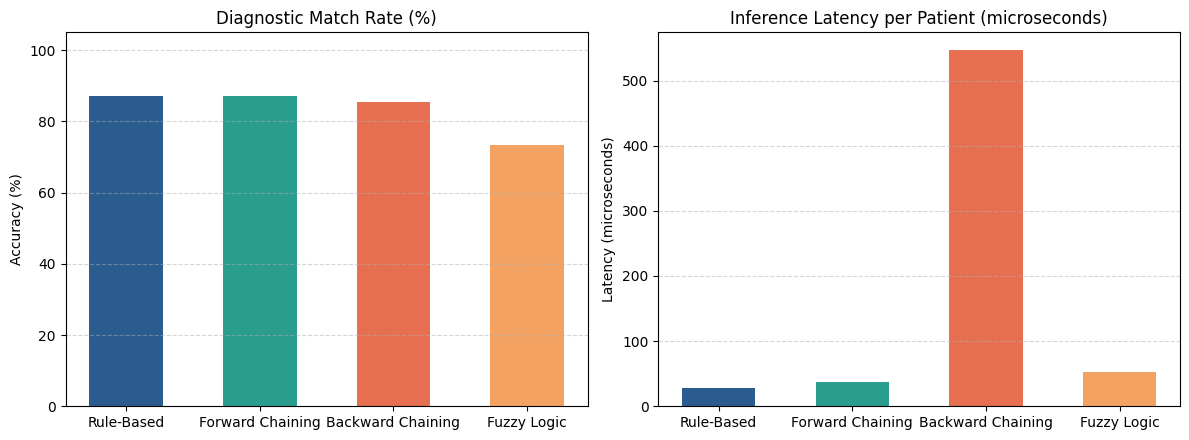

In [7]:
# benchmarking the four methods on the 200 patient dataset
results = []
ground_truths = []
equiv_map = {
    "COVID-19": ["COVID-19", "Pneumonia"],
    "Dengue Fever": ["Dengue Fever", "Dengue"]
}

n_patients = len(df)
latencies = {"Rule-Based": [], "Forward Chaining": [], "Backward Chaining": [], "Fuzzy Logic": []}
correct_counts = {"Rule-Based": 0, "Forward Chaining": 0, "Backward Chaining": 0, "Fuzzy Logic": 0}
coverage_counts = {"Rule-Based": 0, "Forward Chaining": 0, "Backward Chaining": 0, "Fuzzy Logic": 0}

for idx, row in df.iterrows():
    p_dict = row.to_dict()
    gt = str(row.get("diagnosis", "Unknown")).strip()
    ground_truths.append(gt)
    valid_targets = equiv_map.get(gt, [gt])

    # benchmark rule-based
    t0 = time.perf_counter()
    res_rb = rbs_engine.diagnose(p_dict)
    lat_rb = (time.perf_counter() - t0) * 1e6
    latencies["Rule-Based"].append(lat_rb)
    if res_rb["diagnosis"] in valid_targets:
        correct_counts["Rule-Based"] += 1
    if res_rb["diagnosis"] != "Undetermined / Inconclusive":
        coverage_counts["Rule-Based"] += 1

    # benchmark forward chaining
    t0 = time.perf_counter()
    res_fc = fc_engine.infer(p_dict)
    lat_fc = (time.perf_counter() - t0) * 1e6
    latencies["Forward Chaining"].append(lat_fc)
    if res_fc["diagnosis"] in valid_targets:
        correct_counts["Forward Chaining"] += 1
    if res_fc["diagnosis"] != "Undetermined / Inconclusive":
        coverage_counts["Forward Chaining"] += 1

    # benchmark backward chaining
    t0 = time.perf_counter()
    res_bc = bc_engine.infer(p_dict)
    lat_bc = (time.perf_counter() - t0) * 1e6
    latencies["Backward Chaining"].append(lat_bc)
    if res_bc["diagnosis"] in valid_targets:
        correct_counts["Backward Chaining"] += 1
    if res_bc["diagnosis"] != "Undetermined / Inconclusive":
        coverage_counts["Backward Chaining"] += 1

    # benchmark fuzzy logic
    t0 = time.perf_counter()
    res_fz = fuzzy_engine.infer(p_dict)
    lat_fz = (time.perf_counter() - t0) * 1e6
    latencies["Fuzzy Logic"].append(lat_fz)
    if res_fz["diagnosis"] in valid_targets:
        correct_counts["Fuzzy Logic"] += 1
    if res_fz["diagnosis"] != "Undetermined / Inconclusive":
        coverage_counts["Fuzzy Logic"] += 1

# generate benchmark summary table
summary_data = []
for m in ["Rule-Based", "Forward Chaining", "Backward Chaining", "Fuzzy Logic"]:
    acc = (correct_counts[m] / n_patients) * 100.0 if n_patients else 0.0
    cov = (coverage_counts[m] / n_patients) * 100.0 if n_patients else 0.0
    avg_lat = np.mean(latencies[m])
    summary_data.append({
        "Method": m,
        "Accuracy (%)": round(acc, 2),
        "Diagnostic Coverage (%)": round(cov, 2),
        "Mean Latency (microseconds)": round(avg_lat, 2)
    })

benchmark_df = pd.DataFrame(summary_data)
print("Diagnostic Method Comparison Matrix (Evaluated on 200 Patient Records):")
print(benchmark_df.to_string(index=False))

# visualize benchmark results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

methods = benchmark_df["Method"]
colors = ["#2b5c8f", "#2a9d8f", "#e76f51", "#f4a261"]

ax1.bar(methods, benchmark_df["Accuracy (%)"], color=colors, width=0.55)
ax1.set_title("Diagnostic Match Rate (%)")
ax1.set_ylabel("Accuracy (%)")
ax1.set_ylim(0, 105)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

ax2.bar(methods, benchmark_df["Mean Latency (microseconds)"], color=colors, width=0.55)
ax2.set_title("Inference Latency per Patient (microseconds)")
ax2.set_ylabel("Latency (microseconds)")
ax2.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


## Architectural Comparison Matrix

| Evaluation Dimension | Rule-Based Expert System | Forward Chaining | Backward Chaining | Fuzzy Logic (Mamdani) |
| :--- | :--- | :--- | :--- | :--- |
| Reasoning Direction | Direct pattern matching | Data-driven (bottom-up) | Goal-driven (top-down) | Approximate / Soft reasoning |
| Primary Input Handling | Crisp boolean comparisons | Asserted working memory facts | Target hypothesis queries | Fuzzified membership degrees [0, 1] |
| Conflict Resolution | Precondition specificity | Agenda firing priority | Goal tree ordering | Centroid defuzzification |
| Uncertainty Management | Deterministic (all-or-nothing) | Deterministic (fact chaining) | Deterministic (subgoal proof) | Continuous truth degrees |
| Explainability Output | Fired rule identifier and text | Sequential cycle derivation trace | Hierarchical subgoal proof tree | Ranked membership scores and centroid |
| Missing Input Tolerance | Low (unmatched antecedents fail) | Moderate (fires partial abstractions) | High (localizes missing clinical tests) | High (evaluates partial fuzzy support) |
| Execution Complexity | O(R) linear rule scan | O(R * C) multi-cycle propagation | O(R * G) goal tree evaluation | O(R * F) membership calculation |


In [8]:
import gradio as gr

# clinical presets for evaluation
PRESET_CASES = {
    "Patient: Flu (Acute)": {
        "fever": 38.6, "cough": 8, "spo2": 96, "hr": 84, "bp": 120,
        "fatigue": 7, "headache": 4, "nausea": 1, "stomach_pain": 0, "joint_pain": 2, "back_pain": 1, "thirst": 2,
        "rash": False, "bleeding": False, "diarrhea": False, "vomiting": False,
        "sore_throat": True, "body_pain": True, "wheezing": False, "chest_pain": False,
        "shortness_of_breath": False, "night_sweats": False, "stiff_neck": False,
        "dizziness": False, "confusion": False, "sweating": False, "itching": False,
        "eye_redness": False, "watery_eyes": False, "stiffness": False, "urination": "normal"
    },
    "Patient: Pneumonia (Respiratory Distress)": {
        "fever": 38.8, "cough": 9, "spo2": 89, "hr": 98, "bp": 124,
        "fatigue": 8, "headache": 4, "nausea": 1, "stomach_pain": 0, "joint_pain": 1, "back_pain": 1, "thirst": 3,
        "rash": False, "bleeding": False, "diarrhea": False, "vomiting": False,
        "sore_throat": False, "body_pain": False, "wheezing": False, "chest_pain": False,
        "shortness_of_breath": True, "night_sweats": False, "stiff_neck": False,
        "dizziness": False, "confusion": False, "sweating": False, "itching": False,
        "eye_redness": False, "watery_eyes": False, "stiffness": False, "urination": "normal"
    },
    "Patient: Meningitis (Neurological Crisis)": {
        "fever": 38.7, "cough": 2, "spo2": 97, "hr": 92, "bp": 130,
        "fatigue": 7, "headache": 9, "nausea": 4, "stomach_pain": 0, "joint_pain": 2, "back_pain": 2, "thirst": 3,
        "rash": False, "bleeding": False, "diarrhea": False, "vomiting": False,
        "sore_throat": False, "body_pain": False, "wheezing": False, "chest_pain": False,
        "shortness_of_breath": False, "night_sweats": False, "stiff_neck": True,
        "dizziness": True, "confusion": False, "sweating": False, "itching": False,
        "eye_redness": False, "watery_eyes": False, "stiffness": False, "urination": "normal"
    },
    "Patient: Food Poisoning (Gastrointestinal)": {
        "fever": 37.2, "cough": 1, "spo2": 98, "hr": 82, "bp": 118,
        "fatigue": 6, "headache": 3, "nausea": 8, "stomach_pain": 7, "joint_pain": 0, "back_pain": 0, "thirst": 5,
        "rash": False, "bleeding": False, "diarrhea": True, "vomiting": True,
        "sore_throat": False, "body_pain": False, "wheezing": False, "chest_pain": False,
        "shortness_of_breath": False, "night_sweats": False, "stiff_neck": False,
        "dizziness": False, "confusion": False, "sweating": False, "itching": False,
        "eye_redness": False, "watery_eyes": False, "stiffness": False, "urination": "normal"
    },
    "Patient: Healthy (Low Symptom Profile)": {
        "fever": 36.6, "cough": 1, "spo2": 99, "hr": 70, "bp": 115,
        "fatigue": 1, "headache": 1, "nausea": 0, "stomach_pain": 0, "joint_pain": 0, "back_pain": 0, "thirst": 2,
        "rash": False, "bleeding": False, "diarrhea": False, "vomiting": False,
        "sore_throat": False, "body_pain": False, "wheezing": False, "chest_pain": False,
        "shortness_of_breath": False, "night_sweats": False, "stiff_neck": False,
        "dizziness": False, "confusion": False, "sweating": False, "itching": False,
        "eye_redness": False, "watery_eyes": False, "stiffness": False, "urination": "normal"
    }
}

def load_preset(name):
    if not name or name not in PRESET_CASES:
        return [37.0, 0, 98, 75, 120, 0, 0, 0, 0, 0, 0, 0, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, "normal"]
    c = PRESET_CASES[name]
    return [
        c["fever"], c["cough"], c["spo2"], c["hr"], c["bp"],
        c["fatigue"], c["headache"], c["nausea"], c["stomach_pain"], c["joint_pain"], c["back_pain"], c["thirst"],
        c["rash"], c["bleeding"], c["diarrhea"], c["vomiting"],
        c["sore_throat"], c["body_pain"], c["wheezing"], c["chest_pain"],
        c["shortness_of_breath"], c["night_sweats"], c["stiff_neck"],
        c["dizziness"], c["confusion"], c["sweating"], c["itching"],
        c["eye_redness"], c["watery_eyes"], c["stiffness"], c["urination"]
    ]

def run_diagnostic_system(
    method, bc_target,
    fever, cough, spo2, hr, bp,
    fatigue, headache, nausea, stomach_pain, joint_pain, back_pain, thirst,
    rash, bleeding, diarrhea, vomiting,
    sore_throat, body_pain, wheezing, chest_pain,
    shortness_of_breath, night_sweats, stiff_neck,
    dizziness, confusion, sweating, itching,
    eye_redness, watery_eyes, stiffness, urination
):
    patient_dict = {
        "fever_C": fever, "cough": cough, "oxygen_spo2": spo2, "heart_rate": hr, "blood_pressure": bp,
        "fatigue": fatigue, "headache": headache, "nausea": nausea, "stomach_pain": stomach_pain,
        "joint_pain": joint_pain, "back_pain": back_pain, "thirst": thirst,
        "rash": "yes" if rash else "no",
        "bleeding": "yes" if bleeding else "no",
        "diarrhea": "yes" if diarrhea else "no",
        "vomiting": "yes" if vomiting else "no",
        "sore_throat": "yes" if sore_throat else "no",
        "body_pain": "yes" if body_pain else "no",
        "wheezing": "yes" if wheezing else "no",
        "chest_pain": "yes" if chest_pain else "no",
        "shortness_of_breath": "yes" if shortness_of_breath else "no",
        "night_sweats": "yes" if night_sweats else "no",
        "stiff_neck": "yes" if stiff_neck else "no",
        "dizziness": "yes" if dizziness else "no",
        "confusion": "yes" if confusion else "no",
        "sweating": "yes" if sweating else "no",
        "skin_rash": "yes" if rash else "no",
        "itching": "yes" if itching else "no",
        "eye_redness": "yes" if eye_redness else "no",
        "watery_eyes": "yes" if watery_eyes else "no",
        "stiffness": "yes" if stiffness else "no",
        "urination": urination
    }

    if method == "Rule-Based Expert System":
        res = rbs_engine.diagnose(patient_dict)
        diag = res["diagnosis"]
        conf = f"{int(res['confidence'] * 100)}%"
        details = f"Primary Rule: {res['primary_rule']}\nReasoning: {res['reasoning']}\n\nAll Fired Rules:\n" + "\n".join(f"- {r}" for r in res["fired_rules"])
        trace_str = "\n".join(f"[Fired] {r}" for r in res["fired_rules"]) if res["fired_rules"] else "No production rules matched."

    elif method == "Forward Chaining":
        res = fc_engine.infer(patient_dict)
        diag = res["diagnosis"]
        conf = f"{int(res['confidence'] * 100)}%"
        details = f"Deduction Cycles: {res['cycles']}\nReasoning: {res['reasoning']}"
        trace_str = "\n".join(res["trace"])

    elif method == "Backward Chaining":
        res = bc_engine.infer(patient_dict, target_hypothesis=bc_target)
        diag = res["diagnosis"]
        conf = f"{int(res['confidence'] * 100)}%"
        details = f"Goal Tested: {res['goal_tested']}\nStatus: {'PROVEN' if res['proven'] else 'REFUTED'}\nReasoning: {res['reasoning']}"
        trace_str = "\n".join(res["trace"])

    else:
        res = fuzzy_engine.infer(patient_dict)
        diag = res["diagnosis"]
        conf = f"Truth Degree: {res['confidence']}"
        details = f"Calculated Severity Index: {res['severity_score']} / 100\nReasoning: {res['reasoning']}\n\nTop Candidates:\n" + "\n".join(f"- {d}: degree {s}" for d, s in res["ranked_diseases"])
        trace_str = "\n".join(res["trace"])

    r_all_rb = rbs_engine.diagnose(patient_dict)["diagnosis"]
    r_all_fc = fc_engine.infer(patient_dict)["diagnosis"]
    r_all_bc = bc_engine.infer(patient_dict)["diagnosis"]
    r_all_fz = fuzzy_engine.infer(patient_dict)["diagnosis"]

    comp_summary = (
        f"Cross-Method Agreement for this Patient Profile:\n"
        f"1. Rule-Based Expert System : {r_all_rb}\n"
        f"2. Forward Chaining         : {r_all_fc}\n"
        f"3. Backward Chaining        : {r_all_bc}\n"
        f"4. Fuzzy Logic (Mamdani)    : {r_all_fz}"
    )

    return diag, conf, details, trace_str, comp_summary

disease_list = ["Auto (Evaluate All Candidates)"] + sorted(list(set(r["disease"] for r in CLINICAL_RULES)))

with gr.Blocks(title="Clinical Expert Diagnosis System") as demo:
    gr.Markdown("# Clinical Medical Diagnosis Expert System")
    gr.Markdown("Unified Diagnostic Decision Support System comparing Rule-Based, Forward Chaining, Backward Chaining, and Fuzzy Logic.")

    with gr.Row():
        with gr.Column(scale=1):
            method_dropdown = gr.Dropdown(
                choices=["Rule-Based Expert System", "Forward Chaining", "Backward Chaining", "Fuzzy Logic"],
                value="Rule-Based Expert System",
                label="Diagnostic Inference Method"
            )
            bc_target_dropdown = gr.Dropdown(
                choices=disease_list,
                value="Auto (Evaluate All Candidates)",
                label="Backward Chaining Target Hypothesis (Ignored if other method)"
            )
            preset_dropdown = gr.Dropdown(
                choices=list(PRESET_CASES.keys()),
                label="Load Preset Patient Case",
                value="Patient: Flu (Acute)"
            )

        with gr.Column(scale=2):
            with gr.Row():
                fever_input = gr.Slider(minimum=35.0, maximum=42.0, value=38.6, step=0.1, label="Body Temperature (fever_C)")
                cough_input = gr.Slider(minimum=0, maximum=10, value=8, step=1, label="Cough Intensity (0-10)")
                spo2_input = gr.Slider(minimum=70, maximum=100, value=96, step=1, label="Oxygen Saturation SpO2 (%)")
            with gr.Row():
                hr_input = gr.Slider(minimum=40, maximum=180, value=84, step=1, label="Heart Rate (bpm)")
                bp_input = gr.Slider(minimum=80, maximum=220, value=120, step=1, label="Blood Pressure Systolic (mmHg)")
                urination_input = gr.Dropdown(choices=["normal", "frequent"], value="normal", label="Urination Frequency")

    with gr.Row():
        with gr.Column():
            gr.Markdown("### Symptom Severity Ratings (0-10)")
            fatigue_input = gr.Slider(0, 10, value=7, step=1, label="Fatigue")
            headache_input = gr.Slider(0, 10, value=4, step=1, label="Headache")
            nausea_input = gr.Slider(0, 10, value=1, step=1, label="Nausea")
            stomach_input = gr.Slider(0, 10, value=0, step=1, label="Stomach Pain")
            joint_input = gr.Slider(0, 10, value=2, step=1, label="Joint Pain")
            back_input = gr.Slider(0, 10, value=1, step=1, label="Back Pain")
            thirst_input = gr.Slider(0, 10, value=2, step=1, label="Thirst Level")

        with gr.Column():
            gr.Markdown("### Clinical Signs & Physical Exam")
            with gr.Row():
                rash_cb = gr.Checkbox(label="Rash", value=False)
                bleeding_cb = gr.Checkbox(label="Bleeding", value=False)
                diarrhea_cb = gr.Checkbox(label="Diarrhea", value=False)
                vomiting_cb = gr.Checkbox(label="Vomiting", value=False)
            with gr.Row():
                sore_throat_cb = gr.Checkbox(label="Sore Throat", value=True)
                body_pain_cb = gr.Checkbox(label="Body Pain", value=True)
                wheezing_cb = gr.Checkbox(label="Wheezing", value=False)
                chest_pain_cb = gr.Checkbox(label="Chest Pain", value=False)
            with gr.Row():
                sob_cb = gr.Checkbox(label="Shortness of Breath", value=False)
                sweats_cb = gr.Checkbox(label="Night Sweats", value=False)
                stiff_neck_cb = gr.Checkbox(label="Stiff Neck", value=False)
                dizziness_cb = gr.Checkbox(label="Dizziness", value=False)
            with gr.Row():
                confusion_cb = gr.Checkbox(label="Confusion", value=False)
                sweating_cb = gr.Checkbox(label="Sweating", value=False)
                itching_cb = gr.Checkbox(label="Itching", value=False)
                stiffness_cb = gr.Checkbox(label="Joint Stiffness", value=False)
            with gr.Row():
                eye_redness_cb = gr.Checkbox(label="Eye Redness", value=False)
                watery_eyes_cb = gr.Checkbox(label="Watery Eyes", value=False)

    diagnose_btn = gr.Button("Execute Clinical Diagnosis", variant="primary")

    gr.Markdown("## Diagnostic Findings")
    with gr.Row():
        diag_output = gr.Textbox(label="Primary Diagnosis", interactive=False)
        conf_output = gr.Textbox(label="Confidence / Degree", interactive=False)
    with gr.Row():
        details_output = gr.Textbox(label="Reasoning & Findings", lines=5, interactive=False)
        trace_output = gr.Textbox(label="Execution / Inference Trace", lines=5, interactive=False)
    comp_output = gr.Textbox(label="Comparative Engine Agreement", lines=4, interactive=False)

    inputs_list = [
        method_dropdown, bc_target_dropdown,
        fever_input, cough_input, spo2_input, hr_input, bp_input,
        fatigue_input, headache_input, nausea_input, stomach_input, joint_input, back_input, thirst_input,
        rash_cb, bleeding_cb, diarrhea_cb, vomiting_cb,
        sore_throat_cb, body_pain_cb, wheezing_cb, chest_pain_cb,
        sob_cb, sweats_cb, stiff_neck_cb,
        dizziness_cb, confusion_cb, sweating_cb, itching_cb,
        eye_redness_cb, watery_eyes_cb, stiffness_cb, urination_input
    ]

    outputs_list = [diag_output, conf_output, details_output, trace_output, comp_output]

    diagnose_btn.click(fn=run_diagnostic_system, inputs=inputs_list, outputs=outputs_list)

    preset_inputs = [
        fever_input, cough_input, spo2_input, hr_input, bp_input,
        fatigue_input, headache_input, nausea_input, stomach_input, joint_input, back_input, thirst_input,
        rash_cb, bleeding_cb, diarrhea_cb, vomiting_cb,
        sore_throat_cb, body_pain_cb, wheezing_cb, chest_pain_cb,
        sob_cb, sweats_cb, stiff_neck_cb,
        dizziness_cb, confusion_cb, sweating_cb, itching_cb,
        eye_redness_cb, watery_eyes_cb, stiffness_cb, urination_input
    ]
    preset_dropdown.change(fn=load_preset, inputs=[preset_dropdown], outputs=preset_inputs)

# launch interface
demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d7f300d5b20f5b533e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
